# 미션 7 객체인식(Object Detection)

## 목적 : 객체 인식에 대한 강의 이론을 미션 7 실습을 통해 확인한다.
  참고 코드잇 [AI] 스프린트 미션 7 https://www.codeit.kr/topics/sprint-ai-mission-7/lessons/11967

### 데이터셋 정보 및 환경설정
**출처: 캐글 - 옥스포드-IIIT 반려동물 데이터셋, https://www.kaggle.com/datasets/devdgohil/the-oxfordiiit-pet-dataset**

**Context**

<br>Oxford-IIIT Pet Dataset은 옥스퍼드 대학교 시각 기하학 그룹에서 제작한 37개 카테고리의 반려동물 데이터셋으로, 각 카테고리별로 약 100장의 이미지가 포함되어 있습니다. 이미지들은 크기, 자세, 조명 등에서 큰 변화를 보입니다. 모든 이미지에는 품종, 머리 영역(ROI), 픽셀 단위의 트라이맵 분할에 대한 정답 주석이 함께 제공됩니다.

**README**

<br>Omkar M Parkhi, Andrea Vedaldi, Andrew Zisserman, CV Jawahar 저희는 각 클래스당 약 200장의 이미지로 구성된 37개 카테고리의 반려동물 데이터셋을 제작했습니다. 이미지들은 크기, 자세, 조명 면에서 큰 변화를 보입니다. 모든 이미지에는 품종, 머리 ROI, 픽셀 수준의 트라이맵 분할에 대한 정답 주석이 함께 제공됩니다. 
구성: 

-------- 

trimaps/ 데이터셋의 모든 이미지에 대한 트리맵 주석 
				<br>픽셀 주석: 1: 전경 2: 배경 3: 분류되지 않음 
<br>xmls/ PASCAL VOC 형식의 머리 경계 상자 주석 list.txt 데이터셋의 모든 이미지 목록 파일의 각 항목은 다음과 같은 형식을 갖습니다. 
<br>이미지 CLASS-ID SPECIES BREED ID 
<br>ID: 1~37 클래스 ID 
<br>SPECIES: 1 == 고양이, 2 == 개 
<br>BREED ID: 1~25 == 고양이, 1~12 == 개 
<br>첫 글자가 대문자인 이미지는 고양이 이미지이고, 첫 글자가 소문자인 이미지는 개 이미지입니다. trainval.txt 논문에서 사용된 분할 방식을 설명하는 파일입니다. test.txt 임의의 분할 방식을 시도해 보는 것을 권장합니다. 
<br>지원: 

------- 

문의 사항은 Omkar Parkhi(omkar@robots.ox.ac.uk)에게 연락하십시오. 
<br>참고 문헌: 

---------- 

[1] OM Parkhi, A. Vedaldi, A. Zisserman, CV Jawahar Cats and Dogs IEEE Conference on Computer Vision and Pattern Recognition, 2012 
참고: 

---- 

데이터 세트는 연구 목적으로만 제공됩니다. 이 이미지를 사용할 때는 원본 웹사이트의 이용 약관을 준수해야 합니다. 웹사이트 목록은 [1]을 참조하십시오.


In [1]:
# 데이터 불러오기
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zippyz/cats-and-dogs-breeds-classification-oxford-dataset")

print("Path to dataset files:", path)

100%|██████████| 780M/780M [00:12<00:00, 65.8MB/s] 

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1


In [2]:
# 실험 환경 설정
import torch

# GPU 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [3]:
# 데이터 불러오기
import pandas as pd
import os
import cv2
import matplotlib.pyplot as plt

# 파일 경로 설정
trainval_file_path = os.path.join(path, "annotations", "annotations", "trainval.txt")
test_file_path = os.path.join(path, "annotations", "annotations", "test.txt")

# 이미지, Annotation 경로 설정
image_dir = os.path.join(path, "images", "images")
xml_dir = os.path.join(path, "annotations", "annotations", "xmls")

# Train/Validation 파일 읽기
df_trainval = pd.read_csv(trainval_file_path, sep="\s+", header=None)
df_trainval.columns = ["Image", "ClassID", "Species", "BreedID"]

# Test 파일 읽기
df_test = pd.read_csv(test_file_path, sep="\s+", header=None)
df_test.columns = ["Image", "ClassID", "Species", "BreedID"]

# 데이터 크기 확인
print(f"Train/Validation 데이터 수: {len(df_trainval)}")
print(f"Test 데이터 수: {len(df_test)}")

# Annotation 개수 확인
xml_files = [file for file in os.listdir(xml_dir) if file.endswith(".xml")]
print(f"XML 파일 개수: {len(xml_files)}")

<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1601/619249888.py:16: SyntaxWarning: invalid escape sequence '\s'
  df_trainval = pd.read_csv(trainval_file_path, sep="\s+", header=None)
/tmp/ipykernel_1601/619249888.py:20: SyntaxWarning: invalid escape sequence '\s'
  df_test = pd.read_csv(test_file_path, sep="\s+", header=None)


Train/Validation 데이터 수: 3680
Test 데이터 수: 3669
XML 파일 개수: 3686


### 데이터 갯수 확인
- 학습,검증 이미지 : 3,680장
- 테스트 이미지 : 3,669장
- XML 파일 개수 : 3,686장

**궁금증!**
1. 왜이렇게 테스트 이미지가 많은가? README 권장한 테스트 데이터 활용을 해야되나? -> 테스트 데이터도 다 확인해보자
2. 학습, 검증보다 xml이 6장 많다. -> 어쩌면 라벨....이 이상한건 아닐까? 이것도 확인필요

ClassID: 1
Image: Abyssinian_67
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Abyssinian_67.jpg


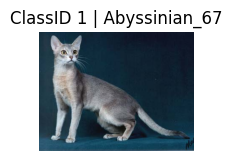

ClassID: 1
Image: Abyssinian_44
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Abyssinian_44.jpg


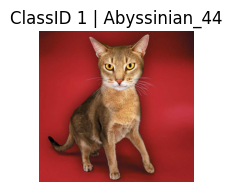

ClassID: 2
Image: american_bulldog_84
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/american_bulldog_84.jpg


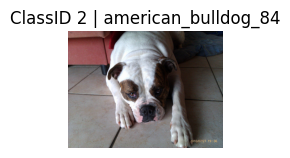

ClassID: 2
Image: american_bulldog_57
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/american_bulldog_57.jpg


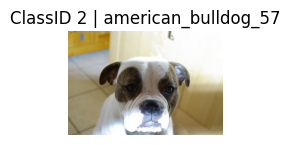

ClassID: 3
Image: american_pit_bull_terrier_84
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/american_pit_bull_terrier_84.jpg


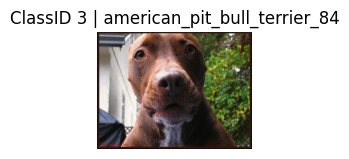

ClassID: 3
Image: american_pit_bull_terrier_56
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/american_pit_bull_terrier_56.jpg


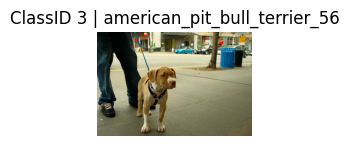

ClassID: 4
Image: basset_hound_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/basset_hound_85.jpg


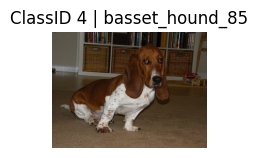

ClassID: 4
Image: basset_hound_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/basset_hound_58.jpg


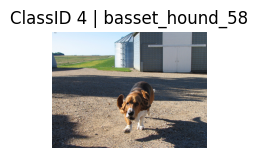

ClassID: 5
Image: beagle_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/beagle_85.jpg


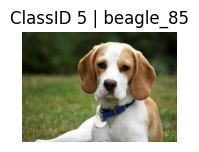

ClassID: 5
Image: beagle_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/beagle_58.jpg


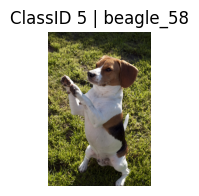

ClassID: 6
Image: Bengal_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Bengal_85.jpg


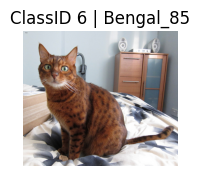

ClassID: 6
Image: Bengal_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Bengal_58.jpg


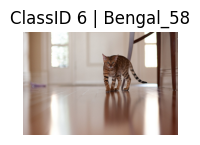

ClassID: 7
Image: Birman_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Birman_85.jpg


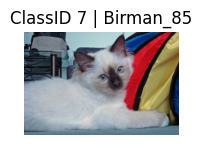

ClassID: 7
Image: Birman_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Birman_58.jpg


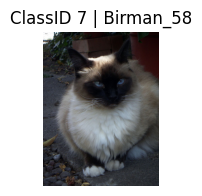

ClassID: 8
Image: Bombay_88
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Bombay_88.jpg


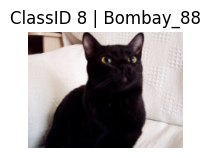

ClassID: 8
Image: Bombay_200
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Bombay_200.jpg


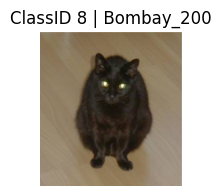

ClassID: 9
Image: boxer_66
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/boxer_66.jpg


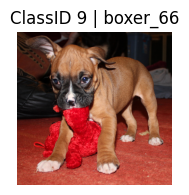

ClassID: 9
Image: boxer_46
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/boxer_46.jpg


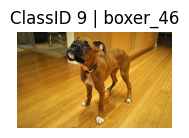

ClassID: 10
Image: British_Shorthair_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/British_Shorthair_85.jpg


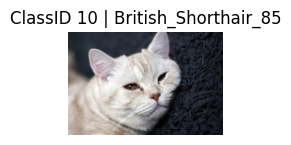

ClassID: 10
Image: British_Shorthair_51
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/British_Shorthair_51.jpg


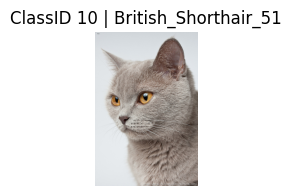

ClassID: 11
Image: chihuahua_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/chihuahua_85.jpg


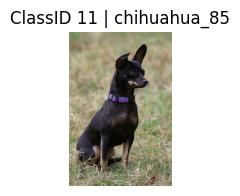

ClassID: 11
Image: chihuahua_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/chihuahua_58.jpg


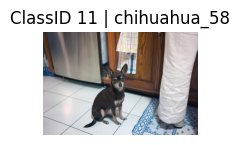

ClassID: 12
Image: Egyptian_Mau_67
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Egyptian_Mau_67.jpg


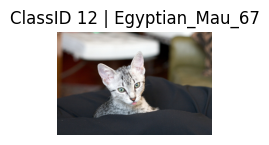

ClassID: 12
Image: Egyptian_Mau_43
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Egyptian_Mau_43.jpg


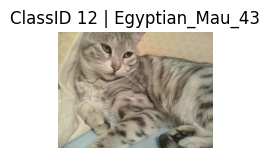

ClassID: 13
Image: english_cocker_spaniel_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/english_cocker_spaniel_85.jpg


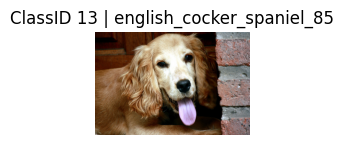

ClassID: 13
Image: english_cocker_spaniel_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/english_cocker_spaniel_58.jpg


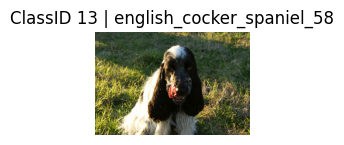

ClassID: 14
Image: english_setter_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/english_setter_85.jpg


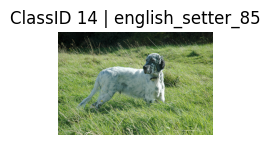

ClassID: 14
Image: english_setter_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/english_setter_58.jpg


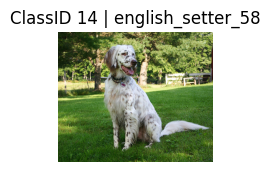

ClassID: 15
Image: german_shorthaired_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/german_shorthaired_85.jpg


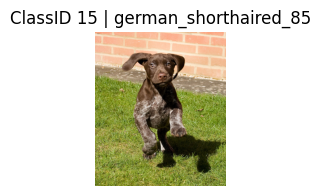

ClassID: 15
Image: german_shorthaired_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/german_shorthaired_58.jpg


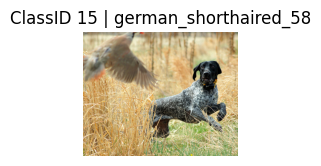

ClassID: 16
Image: great_pyrenees_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/great_pyrenees_85.jpg


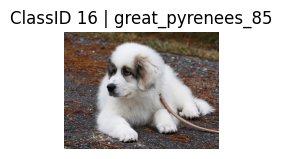

ClassID: 16
Image: great_pyrenees_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/great_pyrenees_58.jpg


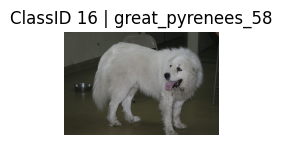

ClassID: 17
Image: havanese_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/havanese_85.jpg


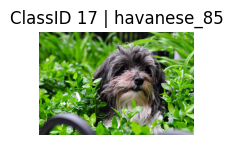

ClassID: 17
Image: havanese_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/havanese_58.jpg


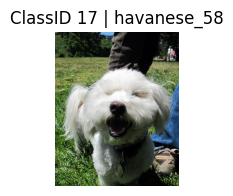

ClassID: 18
Image: japanese_chin_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/japanese_chin_85.jpg


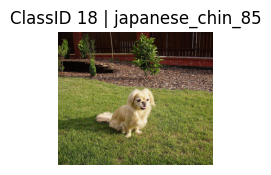

ClassID: 18
Image: japanese_chin_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/japanese_chin_58.jpg


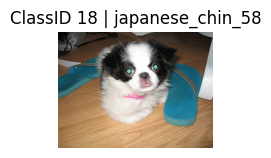

ClassID: 19
Image: keeshond_67
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/keeshond_67.jpg


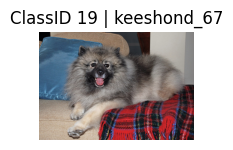

ClassID: 19
Image: keeshond_46
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/keeshond_46.jpg


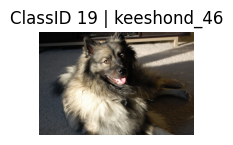

ClassID: 20
Image: leonberger_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/leonberger_85.jpg


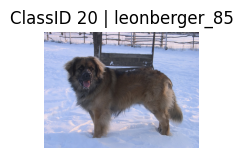

ClassID: 20
Image: leonberger_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/leonberger_58.jpg


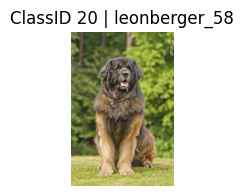

ClassID: 21
Image: Maine_Coon_82
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Maine_Coon_82.jpg


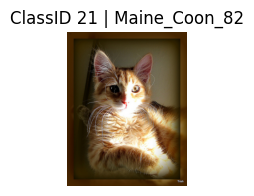

ClassID: 21
Image: Maine_Coon_50
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Maine_Coon_50.jpg


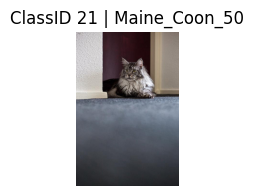

ClassID: 22
Image: miniature_pinscher_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/miniature_pinscher_85.jpg


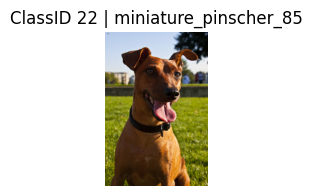

ClassID: 22
Image: miniature_pinscher_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/miniature_pinscher_58.jpg


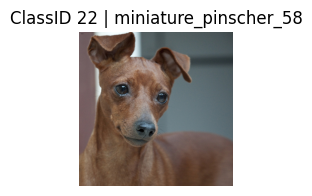

ClassID: 23
Image: newfoundland_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/newfoundland_85.jpg


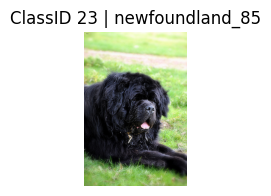

ClassID: 23
Image: newfoundland_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/newfoundland_58.jpg


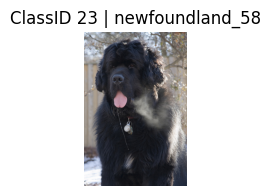

ClassID: 24
Image: Persian_82
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Persian_82.jpg


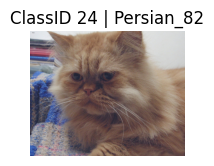

ClassID: 24
Image: Persian_53
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Persian_53.jpg


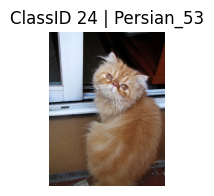

ClassID: 25
Image: pomeranian_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/pomeranian_85.jpg


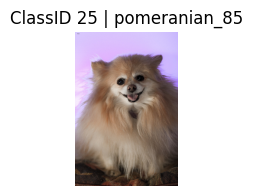

ClassID: 25
Image: pomeranian_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/pomeranian_58.jpg


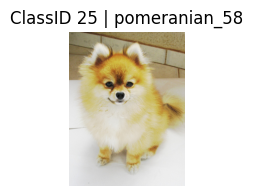

ClassID: 26
Image: pug_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/pug_85.jpg


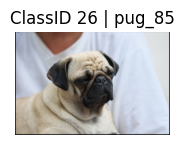

ClassID: 26
Image: pug_57
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/pug_57.jpg


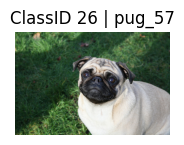

ClassID: 27
Image: Ragdoll_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Ragdoll_85.jpg


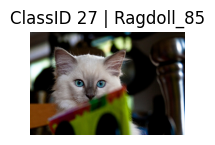

ClassID: 27
Image: Ragdoll_53
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Ragdoll_53.jpg


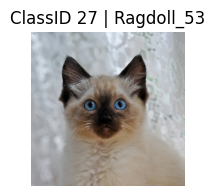

ClassID: 28
Image: Russian_Blue_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Russian_Blue_85.jpg


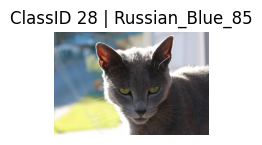

ClassID: 28
Image: Russian_Blue_51
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Russian_Blue_51.jpg


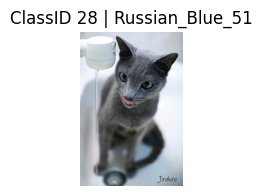

ClassID: 29
Image: saint_bernard_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/saint_bernard_85.jpg


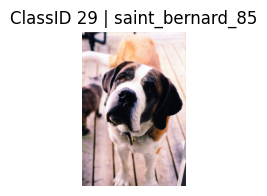

ClassID: 29
Image: saint_bernard_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/saint_bernard_58.jpg


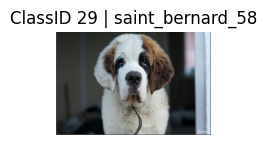

ClassID: 30
Image: samoyed_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/samoyed_85.jpg


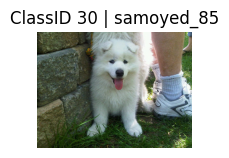

ClassID: 30
Image: samoyed_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/samoyed_58.jpg


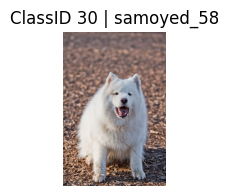

ClassID: 31
Image: scottish_terrier_67
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/scottish_terrier_67.jpg


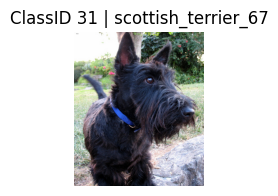

ClassID: 31
Image: scottish_terrier_47
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/scottish_terrier_47.jpg


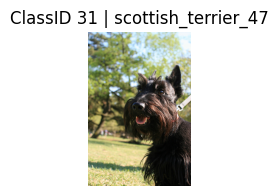

ClassID: 32
Image: shiba_inu_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/shiba_inu_85.jpg


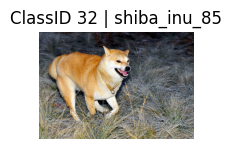

ClassID: 32
Image: shiba_inu_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/shiba_inu_58.jpg


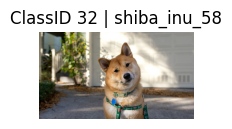

ClassID: 33
Image: Siamese_84
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Siamese_84.jpg


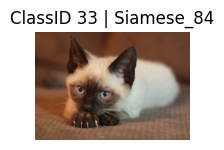

ClassID: 33
Image: Siamese_54
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Siamese_54.jpg


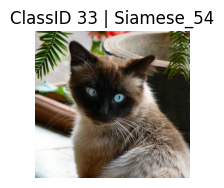

ClassID: 34
Image: Sphynx_83
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Sphynx_83.jpg


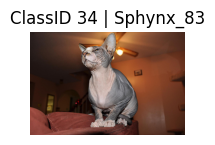

ClassID: 34
Image: Sphynx_45
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/Sphynx_45.jpg


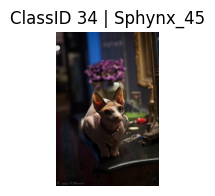

ClassID: 35
Image: staffordshire_bull_terrier_5
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/staffordshire_bull_terrier_5.jpg


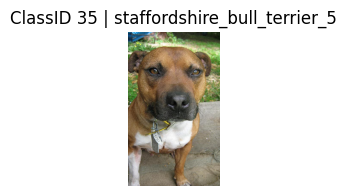

ClassID: 35
Image: staffordshire_bull_terrier_68
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/staffordshire_bull_terrier_68.jpg


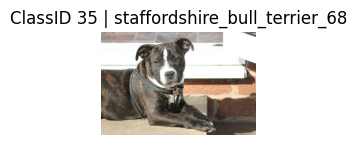

ClassID: 36
Image: wheaten_terrier_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/wheaten_terrier_85.jpg


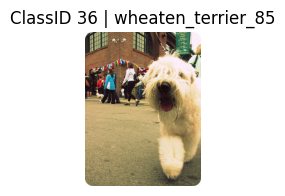

ClassID: 36
Image: wheaten_terrier_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/wheaten_terrier_58.jpg


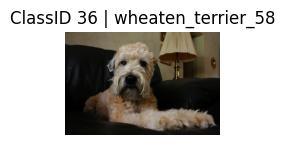

ClassID: 37
Image: yorkshire_terrier_85
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/yorkshire_terrier_85.jpg


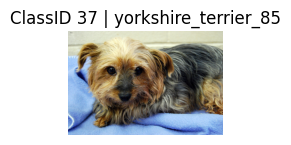

ClassID: 37
Image: yorkshire_terrier_58
파일 경로: /root/.cache/kagglehub/datasets/zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1/images/images/yorkshire_terrier_58.jpg


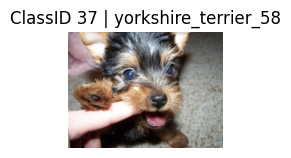

In [6]:
# 1. 왜이렇게 테스트 이미지가 많은가? README 권장한 테스트 데이터 활용을 해야되나? -> 테스트 데이터도 다 확인해보자
# 의사코드
# 각 클래스별 랜덤으로 2개씩 print 해보자
# df_test를 classID로 묶는다.
# class별로 랜덤하게 2개씩 출력한다.
# 문제가 있다면 바로 확인 가능하도록 image랑 파일 경로도 같이  출력한다.

# df_test를 ClassID별로 묶는다.
for class_id, group in df_test.groupby("ClassID"):

    # 각 품종에서 랜덤으로 2장을 선택한다.
    samples = group.sample(n=2, random_state=42)

    for _, row in samples.iterrows():

        # 이미지 이름으로 파일 경로를 완성한다.
        image_name = row["Image"]
        image_path = os.path.join(image_dir, f"{image_name}.jpg")

        # 클래스, 이미지 이름, 파일 경로를 출력한다.
        print(f"ClassID: {class_id}")
        print(f"Image: {image_name}")
        print(f"파일 경로: {image_path}")

        # 이미지 파일을 읽는다.
        image = cv2.imread(image_path)

        # 파일이 없거나 읽을 수 없다면 알리고 다음으로 넘어간다.
        if image is None:
            print("이미지를 불러올 수 없습니다.\n")
            continue

        # OpenCV의 BGR 색상 순서를 RGB로 바꾼다.
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # 이미지를 화면에 표시한다.
        plt.figure(figsize=(2, 2))
        plt.imshow(image)
        plt.title(f"ClassID {class_id} | {image_name}")
        plt.axis("off")
        plt.show()

**테스트 데이터는 잘 들어가 있는걸로 보인다! 아주 귀엽군!**
2. 학습, 검증보다 xml이 6장 많다. -> 어쩌면 라벨....이 이상한건 아닐까? 이것도 확인필요 실시하면서 이것도 클래스 별로 확인해보자

In [7]:
# 2. 학습, 검증보다 xml이 6장 많다. -> 어쩌면 라벨....이 이상한건 아닐까? 이것도 확인필요 실시하면서 이것도 클래스 별로 확인해보자
# 의사코드
# 학습, 검증 데이터 vs XML 각각 비교해보자
# 둘다 파일 이름이 같은지를 먼저 보자 
# df_trainval으로 파일명 추출하고 출력하기
# XML도 동일하게 파일명 추출하기
# 표로 만들어서 비교

# 학습·검증 데이터에서 파일명을 추출한다.
trainval_names = df_trainval["Image"].tolist()

# XML 파일명을 추출한다.
# 이미지 목록과 형식을 맞추기 위해 .xml 확장자를 뺀다.
xml_names = [
    os.path.splitext(file)[0]
    for file in os.listdir(xml_dir)
    if file.endswith(".xml")
]

# 각각 이름순으로 정렬하고 표로 만든다.
# 길이가 달라도 표를 만들 수 있도록 pd.Series를 사용한다.
comparison = pd.DataFrame({
    "학습·검증 파일명": pd.Series(sorted(trainval_names)),
    "XML 파일명": pd.Series(sorted(xml_names))
})

# 각각의 개수를 확인한다.
print(f"학습·검증 파일명 수: {len(trainval_names)}")
print(f"XML 파일명 수: {len(xml_names)}")

# 전체 표를 출력한다.
print(comparison.to_string())

학습·검증 파일명 수: 3680
XML 파일명 수: 3686
                           학습·검증 파일명                         XML 파일명
0                       Abyssinian_1                    Abyssinian_1
1                      Abyssinian_10                   Abyssinian_10
2                     Abyssinian_100                  Abyssinian_100
3                     Abyssinian_101                  Abyssinian_101
4                     Abyssinian_102                  Abyssinian_102
5                     Abyssinian_103                  Abyssinian_103
6                     Abyssinian_104                  Abyssinian_105
7                     Abyssinian_105                  Abyssinian_106
8                     Abyssinian_106                  Abyssinian_107
9                     Abyssinian_107                  Abyssinian_108
10                    Abyssinian_108                  Abyssinian_109
11                    Abyssinian_109                   Abyssinian_11
12                     Abyssinian_11                  Abyssinian_110


In [9]:
# 주르륵 나열만해놓으니깐 뭐가 먼지 모르겠다.
# XML - 학습데이터 = 무엇이 다른지 확인

# 비교하기 쉽게 이름 목록을 집합(set)으로 만든다.
trainval_set = set(trainval_names)
xml_set = set(xml_names)

# 학습·검증 목록에는 있지만 XML은 없는 이름
missing_xml = sorted(trainval_set - xml_set)

# XML은 있지만 학습·검증 목록에는 없는 이름
extra_xml = sorted(xml_set - trainval_set)

print(f"학습 검증 목록에는 있는데 xml은 없다.: {len(missing_xml)}개")
for name in missing_xml:
    print(name)

print(f"\nXML은 있는데, 짝이 되는 사진이 학습·검증 목록에 없다.: {len(extra_xml)}개")
for name in extra_xml:
    print(name)

학습 검증 목록에는 있는데 xml은 없다.: 9개
Abyssinian_104
Bengal_111
Bengal_175
Egyptian_Mau_14
Egyptian_Mau_156
Egyptian_Mau_186
Ragdoll_199
saint_bernard_15
samoyed_10

XML은 있는데, 짝이 되는 사진이 학습·검증 목록에 없다.: 15개
Bombay_11
Bombay_189
Bombay_190
Bombay_192
Egyptian_Mau_129
Egyptian_Mau_183
Siamese_203
english_cocker_spaniel_162
english_cocker_spaniel_163
english_cocker_spaniel_164
english_cocker_spaniel_179
newfoundland_152
newfoundland_153
newfoundland_154
newfoundland_155


**궁즘증!**
저 파일들을 제거하는게 맞을까? XML은 있지만 학습, 검증 목록이 없다면 있어서 무슨 쓸모가 있을까? 과감하게 15개는 학습에서 제외한다.

### EDA
- 바운딩 박스는 올바르게 되어있나?
  <br>목적 : 라벨이 똑바로 안돼어 있으면 학습에 지장을 주기에 확인한다.
  <br>-> print : xml 라벨 각 클래스별로 2개씩 랜덤으로 확인하기 
  <br>-> 바운딩 박스가 없는 이미지가 있는가?

# 계획서
## 연구 목적 : 객체 인식에 대한 강의 이론을 미션 7 실습을 통해 확인한다.
  참고 코드잇 [AI] 스프린트 미션 7 https://www.codeit.kr/topics/sprint-ai-mission-7/lessons/11967
## 데이터정보 및 환경설정
### 데이터셋 소개 (The Oxford-IIIT Pet Dataset)
  - 데이터 불러오기
  <br>- 환경 설정
  <br>- 
### EDA
- 바운딩 박스는 올바르게 되어있나?
  <br>목적 : 라벨이 똑바로 안돼어 있으면 학습에 지장을 주기에 확인한다.
  <br>-> print : xml 라벨 각 클래스별로 2개씩 랜덤으로 확인하기 
  <br>-> 바운딩 박스가 없는 이미지가 있는가?
- 리드미에서 말한 데이터대로 되어 있나? 
  <br>목적 : 설명 자체가 신뢰할 수 있는지 확인한다.
  <br>-> 1은 고양이, 2는 개가 맞는가?
  <br>-> 고양이는 1~25개의 품종이고 개는 1~12 품종이 맞는가?(BREED)
- 데이터 균형은 맞는가?(특정 품종의 사진이 적거나 많거나 하지 않는가?)
  <br>목적 : 정규화가 잘 진행되었는지 확인한다.
  <br>-> 리드미에서 클래스별로 약 200장이라는데 맞는가? 총 37개의 클레스에 몇장씩 있는지 확인하자
  <br>이건 표로 print해서 확인한다.   
- 파일 싸이즈는 다 같은가? (정규화로 픽셀을 바꾼거지 이미지 싸이즈는 그대로일듯)
  <br>목적 : 
  <br>-> 이미지 싸이즈가 너무 다른 것들은 없는가?
데이터 전처리 및 분할 (Train / Test Split)
- 하드웨어 및 소프트웨어 개발 환경
- **방법론**
    - Custom CNN + Sliding Window 아키텍처
    - SSD (Single Shot MultiBox Detector) 아키텍처
    - YOLO (You Only Look Once) 아키텍처
    - 모델별 객체 인식 접근 방식 및 특징 비교
- **실험 결과 및 분석**
    - 평가지표 정의 (mAP, Inference Time, FPS, IoU)
    - 모델별 성능 평가 비교 (종합 결과 테이블)
    - 학습 성능 곡선 분석 (Loss / Accuracy Graph)
    - 실제 객체 탐지 바운딩 박스 시각화 결과 비교
- **결론 및 향후 과제**
    - 연구 결론 요약
    - 한계점 및 향후 연구 발전 방향